# Audio — Semi-supervised (sedikit klip berlabel, banyak tanpa label)
**Kapan dipakai:** hanya sebagian kecil klip train yang berlabel, sisanya tanpa label.

**Idenya (self-training / pseudo-label):** latih di klip berlabel → tebak klip tanpa label →
tebakan yang sangat yakin (≥ `CONFIDENCE_THRESHOLD`) dijadikan label → latih lagi → ulangi.
Putaran terbaik dipilih dengan data validasi.

**Langkah:**
1. Embedding wav2vec2 untuk semua klip.
2. Self-training beberapa putaran, catat skor validasi tiap putaran.
3. Submission dari putaran terbaik. Alternatif `LabelSpreading` ada di bawahnya.

**Data demo:** Speech Commands mini (8 kata), hanya 25% label train yang dipakai.

In [1]:
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.semi_supervised import LabelSpreading
from transformers import AutoFeatureExtractor, Wav2Vec2Model

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/audio/classification"   # GANTI saat lomba
DATA_FOLDER = f"{DATA_FOLDER}/speech_commands_mini"
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"    # kunci jawaban, hanya ada di data demo
PRETRAINED_FOLDER = "Z:/GEMASTIK-DATABASE/pretrained/wav2vec2_base"

ID_COL = "id"
PATH_COL = "path"
LABEL_COL = "label"
SAMPLE_RATE = 16000
CLIP_LENGTH = 16000           # 1 detik per klip
BATCH_SIZE = 32
LABELED_FRACTION = 0.25       # demo: persen label yang dipakai (saat lomba: label kosong = tanpa)
CONFIDENCE_THRESHOLD = 0.90   # pseudo-label hanya untuk tebakan dengan peluang >= ini
N_ROUNDS = 5
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print(train.shape, test.shape)
train.head()

(1200, 3) (320, 3)


,path,label,speaker
0,train/down/7ff085e1_nohash_0.wav,down,7ff085e1
1,train/down/39543cfd_nohash_0.wav,down,39543cfd
2,train/down/3bc21161_nohash_4.wav,down,3bc21161
3,train/down/2f666bb2_nohash_0.wav,down,2f666bb2
4,train/down/bc196f81_nohash_0.wav,down,bc196f81


## Sembunyikan sebagian besar label (HAPUS saat lomba)
Kolom `used_label` = label yang boleh dipakai; kosong (None) = klip tanpa label.
Saat lomba: `train["used_label"] = train[LABEL_COL]` (label kosong sudah kosong dari soal).

In [4]:
labeled, _ = train_test_split(train, train_size=LABELED_FRACTION, random_state=SEED,
                              stratify=train[LABEL_COL])
train["used_label"] = None
train.loc[labeled.index, "used_label"] = train.loc[labeled.index, LABEL_COL]
print("berlabel:", train["used_label"].notna().sum())
print("tanpa label:", train["used_label"].isna().sum())

berlabel: 300
tanpa label: 900


## Langkah 1 — embedding wav2vec2 (rata-rata hidden state)

In [5]:
feature_extractor = AutoFeatureExtractor.from_pretrained(PRETRAINED_FOLDER, local_files_only=True)
encoder = Wav2Vec2Model.from_pretrained(PRETRAINED_FOLDER, local_files_only=True)
encoder.eval()
encoder = encoder.to(DEVICE)


def load_clip(path):
    audio, _ = librosa.load(f"{DATA_FOLDER}/{path}", sr=SAMPLE_RATE)
    audio = np.pad(audio, (0, CLIP_LENGTH))     # tambah nol di belakang
    return audio[:CLIP_LENGTH]                  # lalu potong tepat 1 detik


def extract_embeddings(paths):
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        clips = []
        for path in paths[start:start + BATCH_SIZE]:
            clips.append(load_clip(path))
        inputs = feature_extractor(clips, sampling_rate=SAMPLE_RATE, return_tensors="pt")
        with torch.no_grad():
            output = encoder(inputs.input_values.to(DEVICE))
        mean_over_time = output.last_hidden_state.mean(dim=1)
        batches.append(mean_over_time.cpu().numpy())
    return np.concatenate(batches)


# coba pada 2 klip
example = extract_embeddings(list(train[PATH_COL][:2]))
print("ukuran embedding 2 klip:", example.shape)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: Z:/GEMASTIK-DATABASE/pretrained/wav2vec2_base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ukuran embedding 2 klip: (2, 768)


In [6]:
X_train = extract_embeddings(list(train[PATH_COL]))
X_test = extract_embeddings(list(test[PATH_COL]))
print(X_train.shape, X_test.shape)

(1200, 768) (320, 768)


## Validasi dari data berlabel
30% klip berlabel disisihkan (tidak dilatih, tidak diberi pseudo-label) untuk memilih putaran.

In [7]:
labeled_rows = np.where(train["used_label"].notna())[0]
val_rows, _ = train_test_split(labeled_rows, train_size=0.3, random_state=SEED,
                               stratify=train["used_label"][labeled_rows])
X_val = X_train[val_rows]
y_val = train["used_label"][val_rows].astype(str)
is_val = np.zeros(len(train), dtype=bool)
is_val[val_rows] = True

## Langkah 2 — self-training
Putaran 0 = hanya label asli (baseline). Tiap putaran menambah pseudo-label yang yakin.
Validasi kecil membuat pilihan putaran kasar; kalau validasi tidak naik, putaran 0 = aman.

In [8]:
working_labels = train["used_label"].to_numpy().copy()
working_labels[is_val] = None
history = []
round_models = []
for round_number in range(N_ROUNDS + 1):
    has_label = pd.notna(working_labels)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
    model.fit(X_train[has_label], working_labels[has_label].astype(str))
    round_models.append(model)
    val_f1 = f1_score(y_val, model.predict(X_val), average="macro")
    history.append([round_number, has_label.sum(), val_f1])

    # beri pseudo-label ke klip yang belum berlabel (bukan validasi) dan sangat yakin
    unlabeled = ~has_label & ~is_val
    probabilities = model.predict_proba(X_train[unlabeled])
    confident = probabilities.max(axis=1) >= CONFIDENCE_THRESHOLD
    unlabeled_rows = np.where(unlabeled)[0]
    best_class = probabilities[confident].argmax(axis=1)
    working_labels[unlabeled_rows[confident]] = model.classes_[best_class]

history = pd.DataFrame(history, columns=["round", "n_labels", "val_f1"])
best_round = history["val_f1"].idxmax()
print("putaran terbaik menurut validasi:", best_round)
history.round(4)

putaran terbaik menurut validasi: 0


,round,n_labels,val_f1
0,0,210,0.7355
1,1,552,0.7350
2,2,680,0.7233
3,3,744,0.7020
4,4,773,0.7247
5,5,795,0.7247


## Kurva skor validasi vs putaran

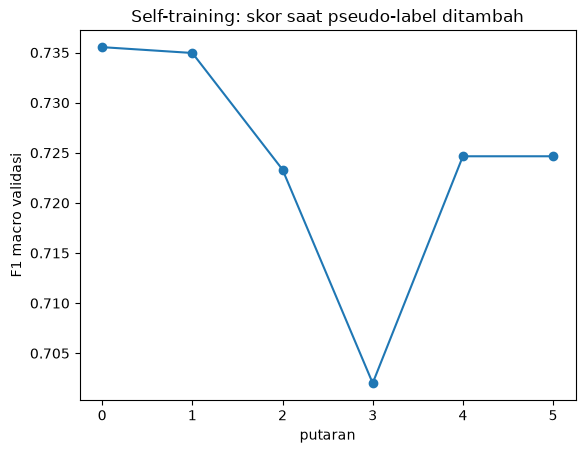

In [9]:
plt.plot(history["round"], history["val_f1"], marker="o")
plt.xlabel("putaran")
plt.ylabel("F1 macro validasi")
plt.title("Self-training: skor saat pseudo-label ditambah")
plt.savefig("kurva.png", dpi=150, bbox_inches="tight")
plt.show()

## Alternatif: LabelSpreading
Label kosong diberi -1 (aturan sklearn). Label menyebar ke 10 tetangga terdekat di ruang
embedding. Untuk dipakai: ganti `predictions` di sel submission dengan `spread_predictions`.

In [10]:
class_names = sorted(train[LABEL_COL].unique())
y_spread = np.full(len(train), -1)
for number, name in enumerate(class_names):
    y_spread[train["used_label"].to_numpy() == name] = number
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
spread = LabelSpreading(kernel="knn", n_neighbors=10, max_iter=100)
spread.fit(X_train_scaled, y_spread)
spread_numbers = spread.predict(X_test_scaled)
spread_predictions = np.array(class_names)[spread_numbers]   # nomor kelas -> nama kelas
print(spread_predictions[:10])

['go' 'left' 'go' 'no' 'no' 'go' 'no' 'yes' 'no' 'up']


## Langkah 3 — submission (model dari putaran terbaik menurut validasi)

In [11]:
model = round_models[best_round]
predictions = model.predict(X_test)

submission = pd.DataFrame()
submission["id"] = test[ID_COL]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,1,down
1,2,down
2,3,no
3,4,right
4,5,down


## Cek dengan kunci jawaban (HAPUS saat lomba)
Skor test tiap putaran: apakah pilihan validasi sama dengan yang terbaik di test?

In [12]:
test_key = pd.read_csv(TEST_KEY_CSV)
for round_number in range(len(round_models)):
    round_predictions = round_models[round_number].predict(X_test)
    test_f1 = f1_score(test_key[LABEL_COL], round_predictions, average="macro")
    print("putaran", round_number, "F1 test:", round(test_f1, 4))
spread_f1 = f1_score(test_key[LABEL_COL], spread_predictions, average="macro")
print("LabelSpreading F1 test:", round(spread_f1, 4))

putaran 0 F1 test: 0.7318
putaran 1 F1 test: 0.7527
putaran 2 F1 test: 0.7496
putaran 3 F1 test: 0.7616
putaran 4 F1 test: 0.7582
putaran 5 F1 test: 0.7679
LabelSpreading F1 test: 0.4138
